# Deep learning for the deadlift

The same idea as notebook 03 (squat), for the deadlift: a Keras network reads the whole pull, frame by frame,
and predicts each IPF deadlift fault:

| Fault | IPF card | What it looks like |
|---|---|---|
| `lockout` | 🔴 red | knees not locked or not standing erect with shoulders back at the top |
| `downward` | 🔵 blue | the bar goes down before lockout |
| `hitching` | 🔵 blue | the knees re-bend so the bar rests on the thighs |
| `feet` | 🟡 yellow | stepping |

**Input:** 96 frames × 10 signals per rep. The deadlift's key signal is the **bar height** (from the wrists),
where the squat's was hip depth. **Output:** 4 sigmoids (multi-label).

> Trained on simulated lifters for now; fine-tune on the MyDeadlift videos (real, side view, CC BY 4.0) when
> they are downloaded.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, keras
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report
from liftjudge.dl import LIFT_FAULTS, LIFT_CHANNELS, synthetic_training_set, build_model, predict_faults
sns.set_theme(style="whitegrid"); keras.utils.set_random_seed(0)
FAULTS = list(LIFT_FAULTS["deadlift"])
print("Keras", keras.__version__, "backend:", keras.backend.backend())

Keras 3.15.1 backend: torch


## 1. Data: 1,500 deadlifts from 60 simulated lifters

In [2]:
X, Y, meta = synthetic_training_set(n_reps=1500, n_lifters=60, seed=0, lift="deadlift")
print("X:", X.shape, " Y:", Y.shape)
print("signals:", LIFT_CHANNELS["deadlift"])
print("fault rate:", dict(zip(FAULTS, Y.mean(0).round(2))), " good lifts:", round((Y.sum(1) == 0).mean(), 2))

X: (1500, 96, 10)  Y: (1500, 4)
signals: ('bar_height', 'hip_height', 'bar_vel', 'knee_angle', 'hip_angle', 'ankle_dx', 'ankle_dy', 'bar_dx', 'leg_conf', 'duration')
fault rate: {'lockout': np.float32(0.18), 'downward': np.float32(0.16), 'hitching': np.float32(0.18), 'feet': np.float32(0.18)}  good lifts: 0.45


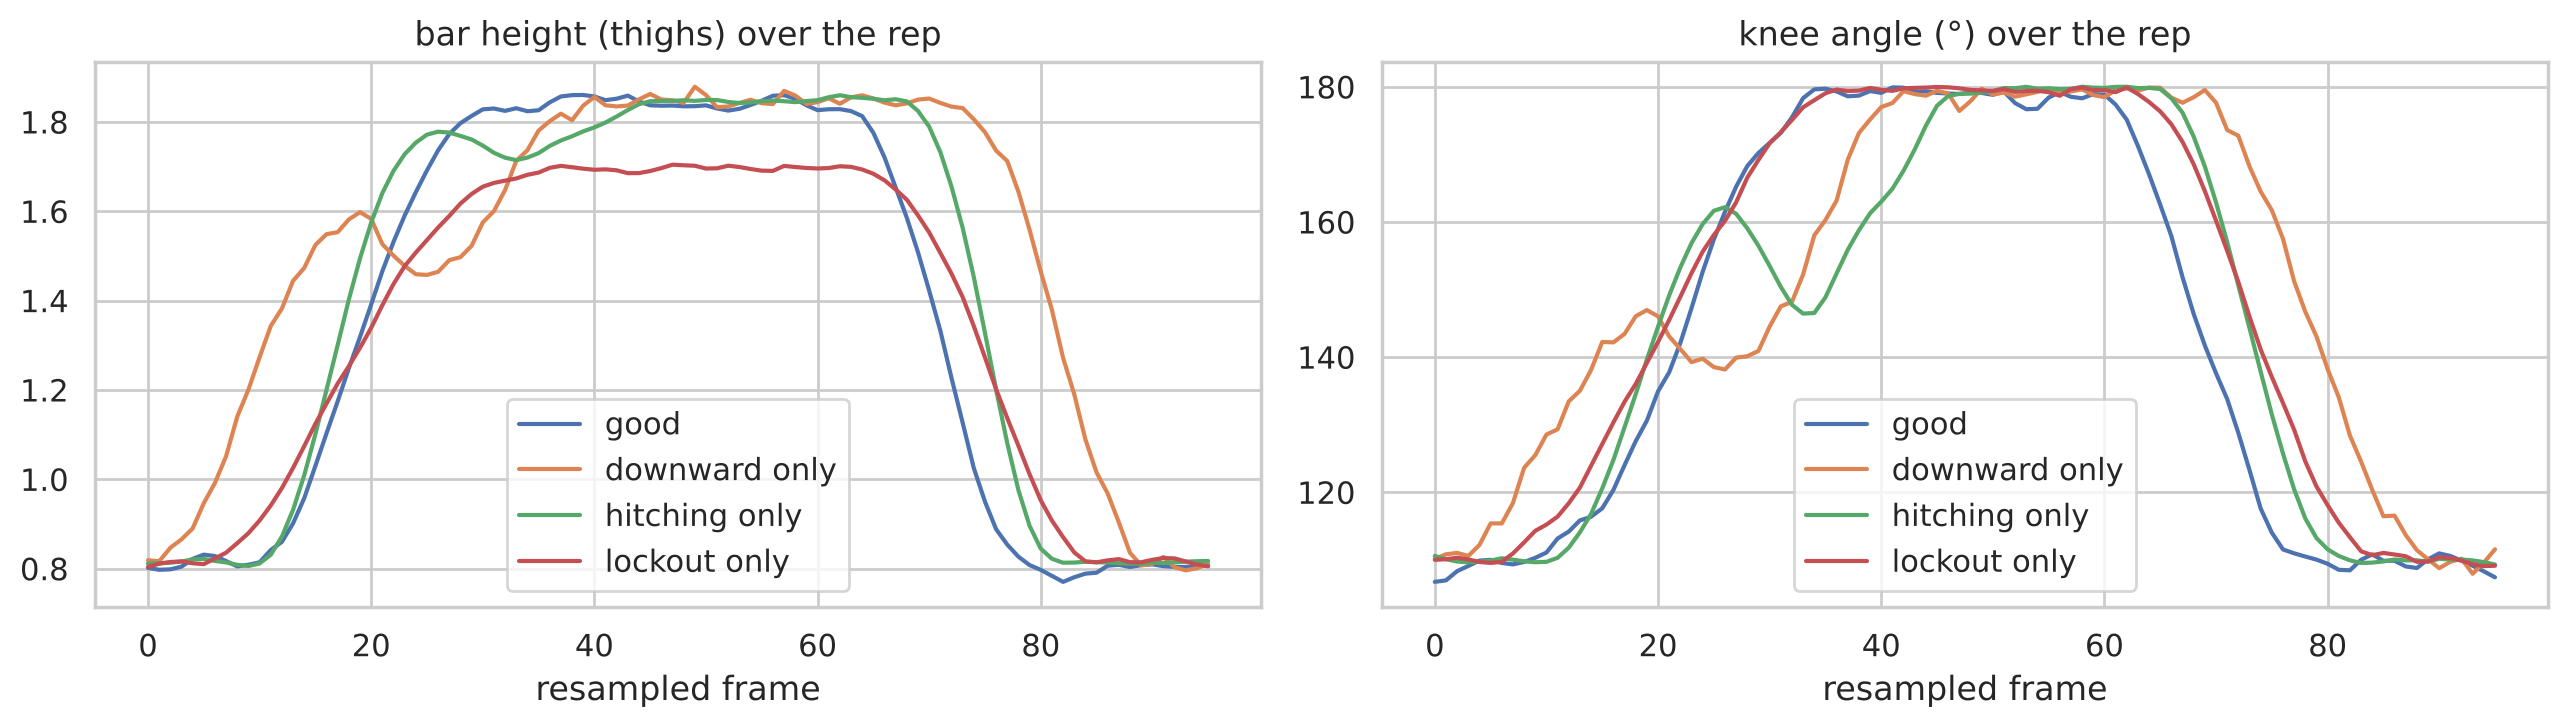

In [3]:
ch = LIFT_CHANNELS["deadlift"].index("bar_height"), LIFT_CHANNELS["deadlift"].index("knee_angle")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for name, mask in {"good": Y.sum(1) == 0, "downward only": (Y[:, 1] == 1) & (Y.sum(1) == 1),
                   "hitching only": (Y[:, 2] == 1) & (Y.sum(1) == 1), "lockout only": (Y[:, 0] == 1) & (Y.sum(1) == 1)}.items():
    i = np.flatnonzero(mask)[0]
    ax[0].plot(X[i, :, ch[0]] * 2, label=name); ax[1].plot(X[i, :, ch[1]] * 180, label=name)
ax[0].set_title("bar height (thighs) over the rep"); ax[1].set_title("knee angle (°) over the rep")
for a in ax: a.set_xlabel("resampled frame"); a.legend()
plt.tight_layout()

## 2. Split by lifter, build and train

train 950 reps / 38 lifters | val 263 | test 287 / 12 lifters


Model: "rep_fault_net_deadlift"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rep_signals (InputLayer)        │ (None, 96, 10)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalize (Normalization)       │ (None, 96, 10)         │            21 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv1D)                  │ (None, 96, 32)         │         1,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 96, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv1D)                  │ (None, 96, 48)         │         7,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool (MaxPooling1D)             │ (None, 48, 48)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (Bidirectional)             │ (None, 64)             │        15,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ faults (Dense)                  │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,465 (107.29 KB)

 Trainable params: 27,380 (106.95 KB)

 Non-trainable params: 85 (340.00 B)

32 epochs, best val_loss 0.0010


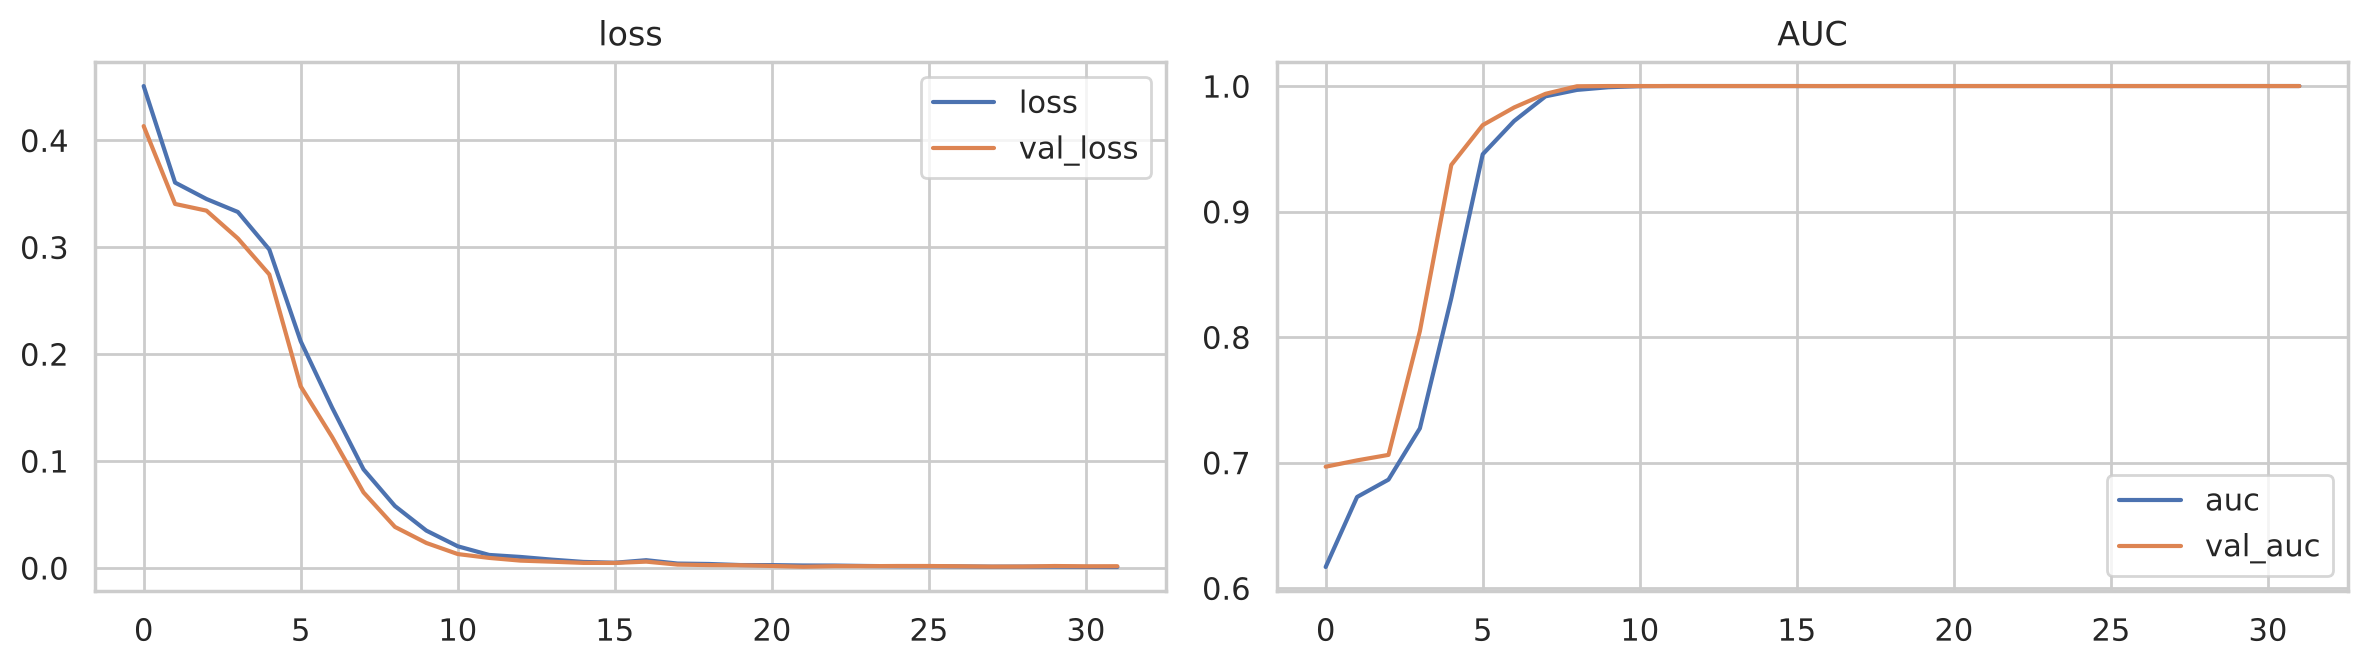

In [4]:
g = meta.lifter.to_numpy()
trv, te = next(GroupShuffleSplit(test_size=0.2, random_state=1).split(X, Y, g))
tr_i, va_i = next(GroupShuffleSplit(test_size=0.2, random_state=2).split(X[trv], Y[trv], g[trv]))
tr, va = trv[tr_i], trv[va_i]
print(f"train {len(tr)} reps / {len(set(g[tr]))} lifters | val {len(va)} | test {len(te)} / {len(set(g[te]))} lifters")
model = build_model(X[tr], lift="deadlift")
model.summary()
stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
hist = model.fit(X[tr], Y[tr], validation_data=(X[va], Y[va]), epochs=60, batch_size=32, callbacks=[stop], verbose=0)
h = pd.DataFrame(hist.history)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
h[["loss", "val_loss"]].plot(ax=ax[0], title="loss"); h[["auc", "val_auc"]].plot(ax=ax[1], title="AUC")
plt.tight_layout(); print(f"{len(h)} epochs, best val_loss {h.val_loss.min():.4f}")

## 3. Rules vs neural network, on lifters it has never seen

precision            recall                F1       
method   neural net  rules neural net  rules neural net  rules
fault                                                         
lockout         1.0  1.000        1.0  0.966        1.0  0.983
downward        1.0  0.495        1.0  1.000        1.0  0.662
hitching        1.0  0.658        1.0  1.000        1.0  0.794
feet            1.0  1.000        1.0  1.000        1.0  1.000

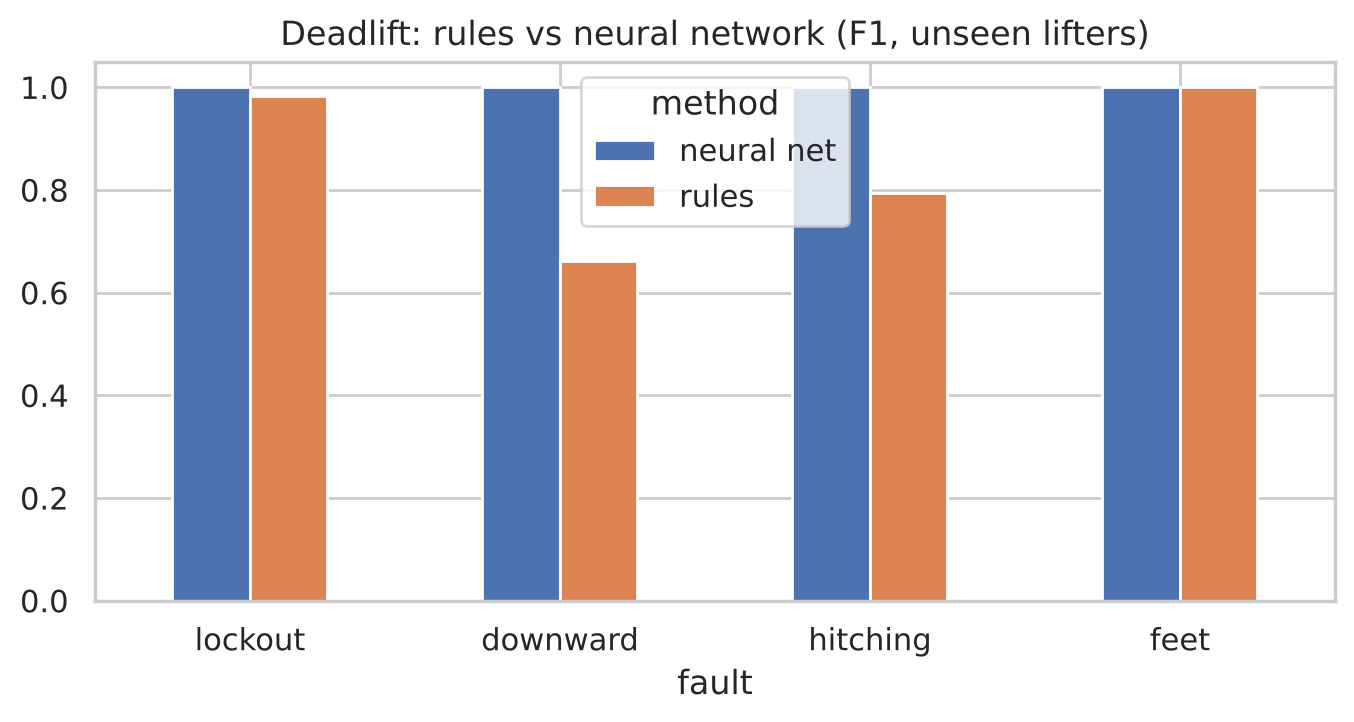

In [5]:
P = model.predict(X[te], verbose=0); pred = (P >= 0.5).astype(int)
rules = meta.iloc[te][[f"rule_{k}" for k in FAULTS]].to_numpy().astype(int)
rows = [{"fault": f, "method": m, "precision": precision_score(Y[te, k], p[:, k], zero_division=0),
         "recall": recall_score(Y[te, k], p[:, k], zero_division=0), "F1": f1_score(Y[te, k], p[:, k], zero_division=0)}
        for k, f in enumerate(FAULTS) for m, p in (("rules", rules), ("neural net", pred))]
cmp = pd.DataFrame(rows)
ax = cmp.pivot(index="fault", columns="method", values="F1").loc[FAULTS].plot.bar(figsize=(8, 3.5), rot=0)
ax.set_ylim(0, 1.05); ax.set_title("Deadlift: rules vs neural network (F1, unseen lifters)")
cmp.pivot(index="fault", columns="method", values=["precision", "recall", "F1"]).loc[FAULTS].round(3)

In [6]:
true_nolift = (Y[te].sum(1) > 0).astype(int)
for name, p in (("rules", (rules.sum(1) > 0).astype(int)), ("neural net", (pred.sum(1) > 0).astype(int))):
    print(f"=== {name}"); print(classification_report(true_nolift, p, target_names=["good lift", "no lift"], digits=3))

=== rules
              precision    recall  f1-score   support

   good lift      0.992     1.000     0.996       123
     no lift      1.000     0.994     0.997       164

    accuracy                          0.997       287
   macro avg      0.996     0.997     0.996       287
weighted avg      0.997     0.997     0.997       287

=== neural net
              precision    recall  f1-score   support

   good lift      1.000     1.000     1.000       123
     no lift      1.000     1.000     1.000       164

    accuracy                          1.000       287
   macro avg      1.000     1.000     1.000       287
weighted avg      1.000     1.000     1.000       287



**Why the rules lose on downward vs hitching:** a hitch makes the bar dip a little while the knees re-bend, so the
downward-movement rule fires on hitches too. Both are blue cards, so the *verdict* is right, but the *reason* is
partly wrong. The network separates them because it sees the knee angle and the bar together over time.

## 4. Save, and use it

In [7]:
(ROOT / "models").mkdir(exist_ok=True)
model.save(ROOT / "models" / "rep_fault_net_deadlift.keras")
from liftjudge import analyze_pose
from liftjudge.synthetic import make_deadlift
res = analyze_pose(make_deadlift(hitch=True, seed=99), "deadlift")
print(res.summary())
predict_faults(model, res).round(3)

Rep 1: NO LIFT  [blue card]
   ok Knees locked at the top (180°)
   ok Standing erect, shoulders back (180°)
   X  Downward movement of the bar before lockout (0.07 thighs)
   X  Hitching: knees re-bent 19° with the bar on the thighs
   ok Feet stayed in place


,rep,lockout,downward,hitching,feet,dl_label
0,1,0.001,0.0,1.0,0.0,NO LIFT


## Takeaways and next step
- On simulated lifters the network learns all four deadlift faults and tells hitching from a plain downward
  movement, which the threshold rules mix up.
- These are best-case numbers: simulated pulls are clean. **Next:** run the MyDeadlift videos (191 real side-view
  reps) through the pipeline and fine-tune with `fine_tune()` (freeze the early layers, retrain the head).